In [162]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [163]:
# X: [час подготовки, число попыток], y: сдал экзамен (1) или нет (0)
X = np.array([
    [1, 1], [2, 1], [2, 2], [3, 2],
    [7, 8], [8, 7], [9, 9], [8, 9],
])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

In [164]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [165]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [166]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

In [167]:
X_train, X_test, y_train, y_test

(array([[1, 1],
        [8, 9],
        [2, 2],
        [7, 8],
        [3, 2],
        [9, 9]]),
 array([[2, 1],
        [8, 7]]),
 array([0, 1, 0, 1, 0, 1]),
 array([0, 1]))

In [168]:
y_pred, y_prob

(array([0, 1]),
 array([[0.98219315, 0.01780685],
        [0.069229  , 0.930771  ]]))

In [169]:
import pandas as pd

In [170]:
df = pd.DataFrame(y_prob, index = [f"объект {[int(v) for v in x]}" for x in X_test], columns=["P(класс 0)", "P(класс 1)"])
df

,P(класс 0),P(класс 1)
"объект [2, 1]",0.982193,0.017807
"объект [8, 7]",0.069229,0.930771


In [171]:
print(accuracy_score(y_true=y_test, y_pred=y_pred))

1.0


In [172]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [173]:
model.coef_, model.intercept_, X_test

(array([[0.48378793, 0.61767846]]),
 array([-5.5954592]),
 array([[2, 1],
        [8, 7]]))

In [174]:
w = model.coef_[0]
b = model.intercept_[0]

print(f"w = {w}")
print(f"b = {b}")

z = X_test @ w + b
print(f"z = {z}")

w = [0.48378793 0.61767846]
b = -5.595459198589175
z = [-4.01020488  2.59859348]


In [175]:
p_manual = sigmoid(z)
print(f"P(1) через функцию = {p_manual}")
print(f"P(0) через функцию = {1 - p_manual}")

P(1) через функцию = [0.01780685 0.930771  ]
P(0) через функцию = [0.98219315 0.069229  ]


In [176]:
print(f"P(1) от модели = {y_prob[:, 1]}")
print(f"P(0) от модели = {y_prob[:, 0]}")

P(1) от модели = [0.01780685 0.930771  ]
P(0) от модели = [0.98219315 0.069229  ]


In [177]:
import matplotlib.pyplot as plt

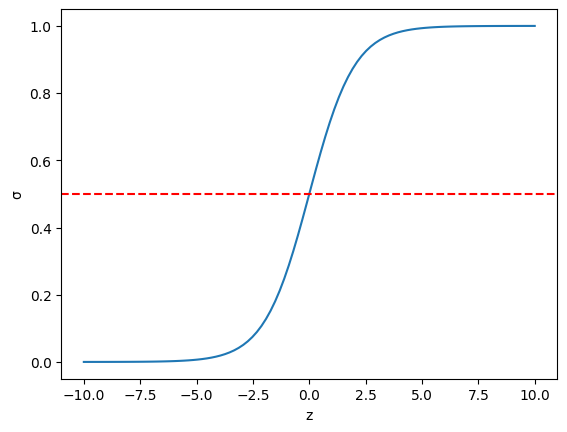

In [178]:
z = np.linspace(-10, 10, 100)
p = sigmoid(z)

plt.plot(z, p)
plt.axhline(0.5, color='red', linestyle='--')
plt.xlabel('z')
plt.ylabel('\u03c3')
plt.show()

In [179]:
from sklearn.metrics import log_loss

In [180]:
loss = log_loss(y_true=y_test, y_pred=y_pred)
loss

2.2204460492503136e-16